In [14]:
from pathlib import Path
from collections import defaultdict
import hashlib

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

In [15]:
# Chemin du dataset
DATA_DIR = Path("../Data")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

IMG_SIZE = (224, 224)

RANDOM_STATE = 42

print("Chemin du dataset :", DATA_DIR.resolve())
print("Dataset existant :", DATA_DIR.exists())
print("Taille cible :", IMG_SIZE)

Chemin du dataset : C:\Users\ajbba\Desktop\YOUCODE-IA\BrainScan\Data
Dataset existant : True
Taille cible : (224, 224)


In [16]:
CLASSES = sorted([
    folder.name
    for folder in DATA_DIR.iterdir()
    if folder.is_dir()
])

print("Classes détectées :", CLASSES)
print("Nombre de classes :", len(CLASSES))

Classes détectées : ['glioma', 'meningioma', 'notumor', 'pituitary']
Nombre de classes : 4


In [17]:
extension_counts = defaultdict(int)
unsupported_files = []

for class_name in CLASSES:
    class_dir = DATA_DIR / class_name

    for file_path in class_dir.iterdir():
        if not file_path.is_file():
            continue

        extension = file_path.suffix.lower()

        if extension in IMAGE_EXTENSIONS:
            extension_counts[extension] += 1
        else:
            unsupported_files.append(str(file_path))

print("Nombre de fichiers par extension :")

for extension, count in sorted(extension_counts.items()):
    print(f"{extension} : {count}")

print("\nNombre de fichiers avec extension non acceptée :",
      len(unsupported_files))

Nombre de fichiers par extension :
.jpg : 7023

Nombre de fichiers avec extension non acceptée : 0


In [18]:
# Stocker les images et leurs labels
images = []
labels = []
image_paths = []

# Suivre les empreintes des images déjà chargées
seen_hashes = {}

# Compteurs pour le contrôle qualité
error_files = []
duplicate_files = []
cross_class_duplicates = []

for class_name in CLASSES:
    class_dir = DATA_DIR / class_name

    for image_path in sorted(class_dir.iterdir()):

        # Ignorer les dossiers
        if not image_path.is_file():
            continue

        # Vérifier l'extension
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            # Lire l'image
            image = cv2.imread(str(image_path))

            # Vérifier si l'image est lisible
            if image is None:
                error_files.append(str(image_path))
                continue

            # Calculer une empreinte du contenu original
            image_hash = hashlib.sha256(
                image_path.read_bytes()
            ).hexdigest()

            # Vérifier si le contenu a déjà été rencontré
            if image_hash in seen_hashes:

                previous_class = seen_hashes[image_hash]["class"]

                if previous_class != class_name:
                    cross_class_duplicates.append({
                        "image_path": str(image_path),
                        "class": class_name,
                        "previous_class": previous_class
                    })
                else:
                    duplicate_files.append(str(image_path))

                continue

            # Enregistrer la première occurrence
            seen_hashes[image_hash] = {
                "image_path": str(image_path),
                "class": class_name
            }

            # Redimensionner l'image
            image = cv2.resize(image, IMG_SIZE)

            # Convertir BGR vers RGB
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            # Ajouter l'image et son label
            images.append(image)
            labels.append(class_name)
            image_paths.append(str(image_path))

        except Exception as error:
            print(f"Erreur pour {image_path} : {error}")
            error_files.append(str(image_path))

print("Images chargées :", len(images))
print("Labels chargés :", len(labels))
print("Fichiers illisibles ou en erreur :", len(error_files))
print("Doublons ignorés dans la même classe :", len(duplicate_files))
print("Doublons trouvés entre classes différentes :",
      len(cross_class_duplicates))

Images chargées : 6726
Labels chargés : 6726
Fichiers illisibles ou en erreur : 0
Doublons ignorés dans la même classe : 297
Doublons trouvés entre classes différentes : 0


In [19]:
# Convertir les listes en tableaux NumPy
X = np.array(images, dtype=np.uint8)
y = np.array(labels)
paths = np.array(image_paths)

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("Dimensions de paths :", paths.shape)

print("\nType de X :", X.dtype)
print("Type de y :", y.dtype)

# Vérifier la correspondance entre images et labels
assert len(X) == len(y) == len(paths)

print("\nVérification réussie : chaque image possède un label.")

Dimensions de X : (6726, 224, 224, 3)
Dimensions de y : (6726,)
Dimensions de paths : (6726,)

Type de X : uint8
Type de y : <U10

Vérification réussie : chaque image possède un label.


Nombre d'images par classe :


,Nombre d'images
glioma,1620
meningioma,1635
notumor,1731
pituitary,1740


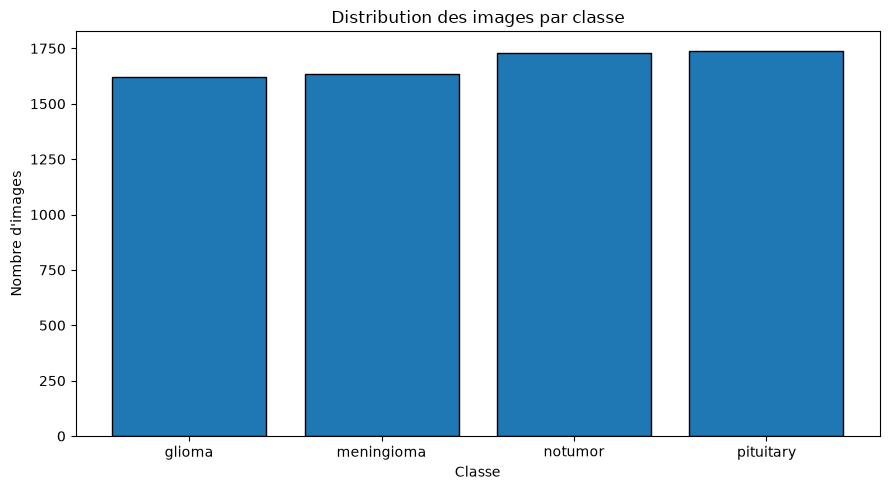

In [20]:
# Compter les images de chaque classe
class_counts = pd.Series(y).value_counts().reindex(
    CLASSES,
    fill_value=0
)

print("Nombre d'images par classe :")
display(class_counts.to_frame("Nombre d'images"))

# Créer le graphique
plt.figure(figsize=(9, 5))

plt.bar(
    class_counts.index,
    class_counts.values,
    edgecolor="black"
)

plt.title("Distribution des images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

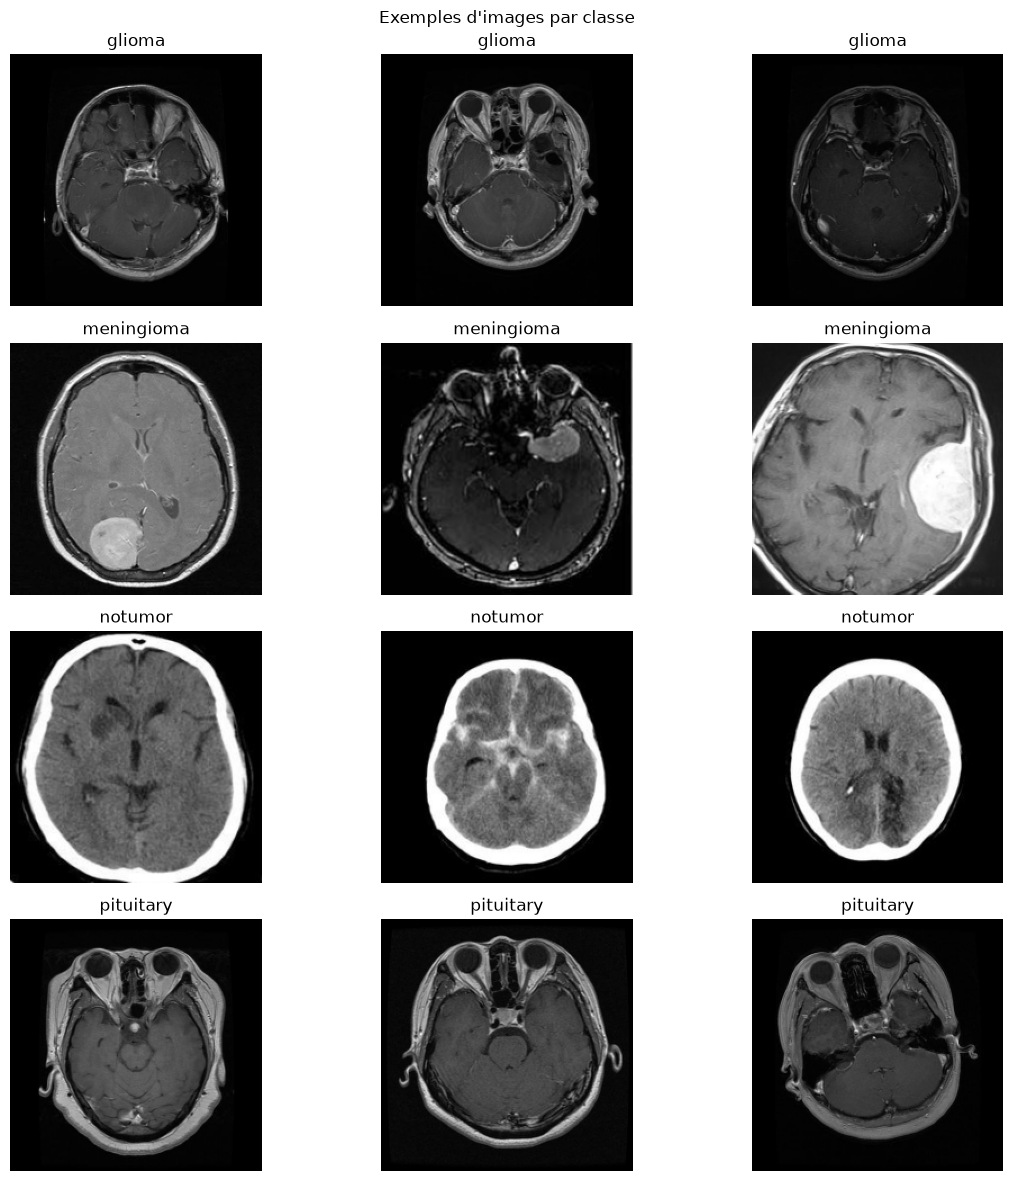

In [21]:
# Nombre d'images à afficher par classe
N_SAMPLES = 3

fig, axes = plt.subplots(
    len(CLASSES),
    N_SAMPLES,
    figsize=(12, 12)
)

for class_index, class_name in enumerate(CLASSES):

    # Indices des images appartenant à cette classe
    class_indices = np.where(y == class_name)[0]

    # Sélectionner jusqu'à N_SAMPLES images
    selected_indices = class_indices[:N_SAMPLES]

    for column_index in range(N_SAMPLES):

        ax = axes[class_index, column_index]

        if column_index < len(selected_indices):

            image_index = selected_indices[column_index]
            image = X[image_index]

            ax.imshow(image)
            ax.set_title(class_name)

        ax.axis("off")

plt.suptitle("Exemples d'images par classe")
plt.tight_layout()
plt.show()

In [ ]:
# Calculer les pourcentages par classe
class_percentages = (
    class_counts / class_counts.sum() * 100
).round(2)

balance_table = pd.DataFrame({
    "Nombre d'images": class_counts,
    "Pourcentage (%)": class_percentages
})

display(balance_table)

# Calculer le rapport entre la classe la plus grande et la plus petite
non_zero_counts = class_counts[class_counts > 0]

if len(non_zero_counts) > 0:
    balance_ratio = non_zero_counts.max() / non_zero_counts.min()

    print("Rapport max/min :", round(balance_ratio, 2))